
# <span style="color:rgb(213,80,0)">**Κεφάλαιο 2**</span>

##  **Άσκηση 1.**


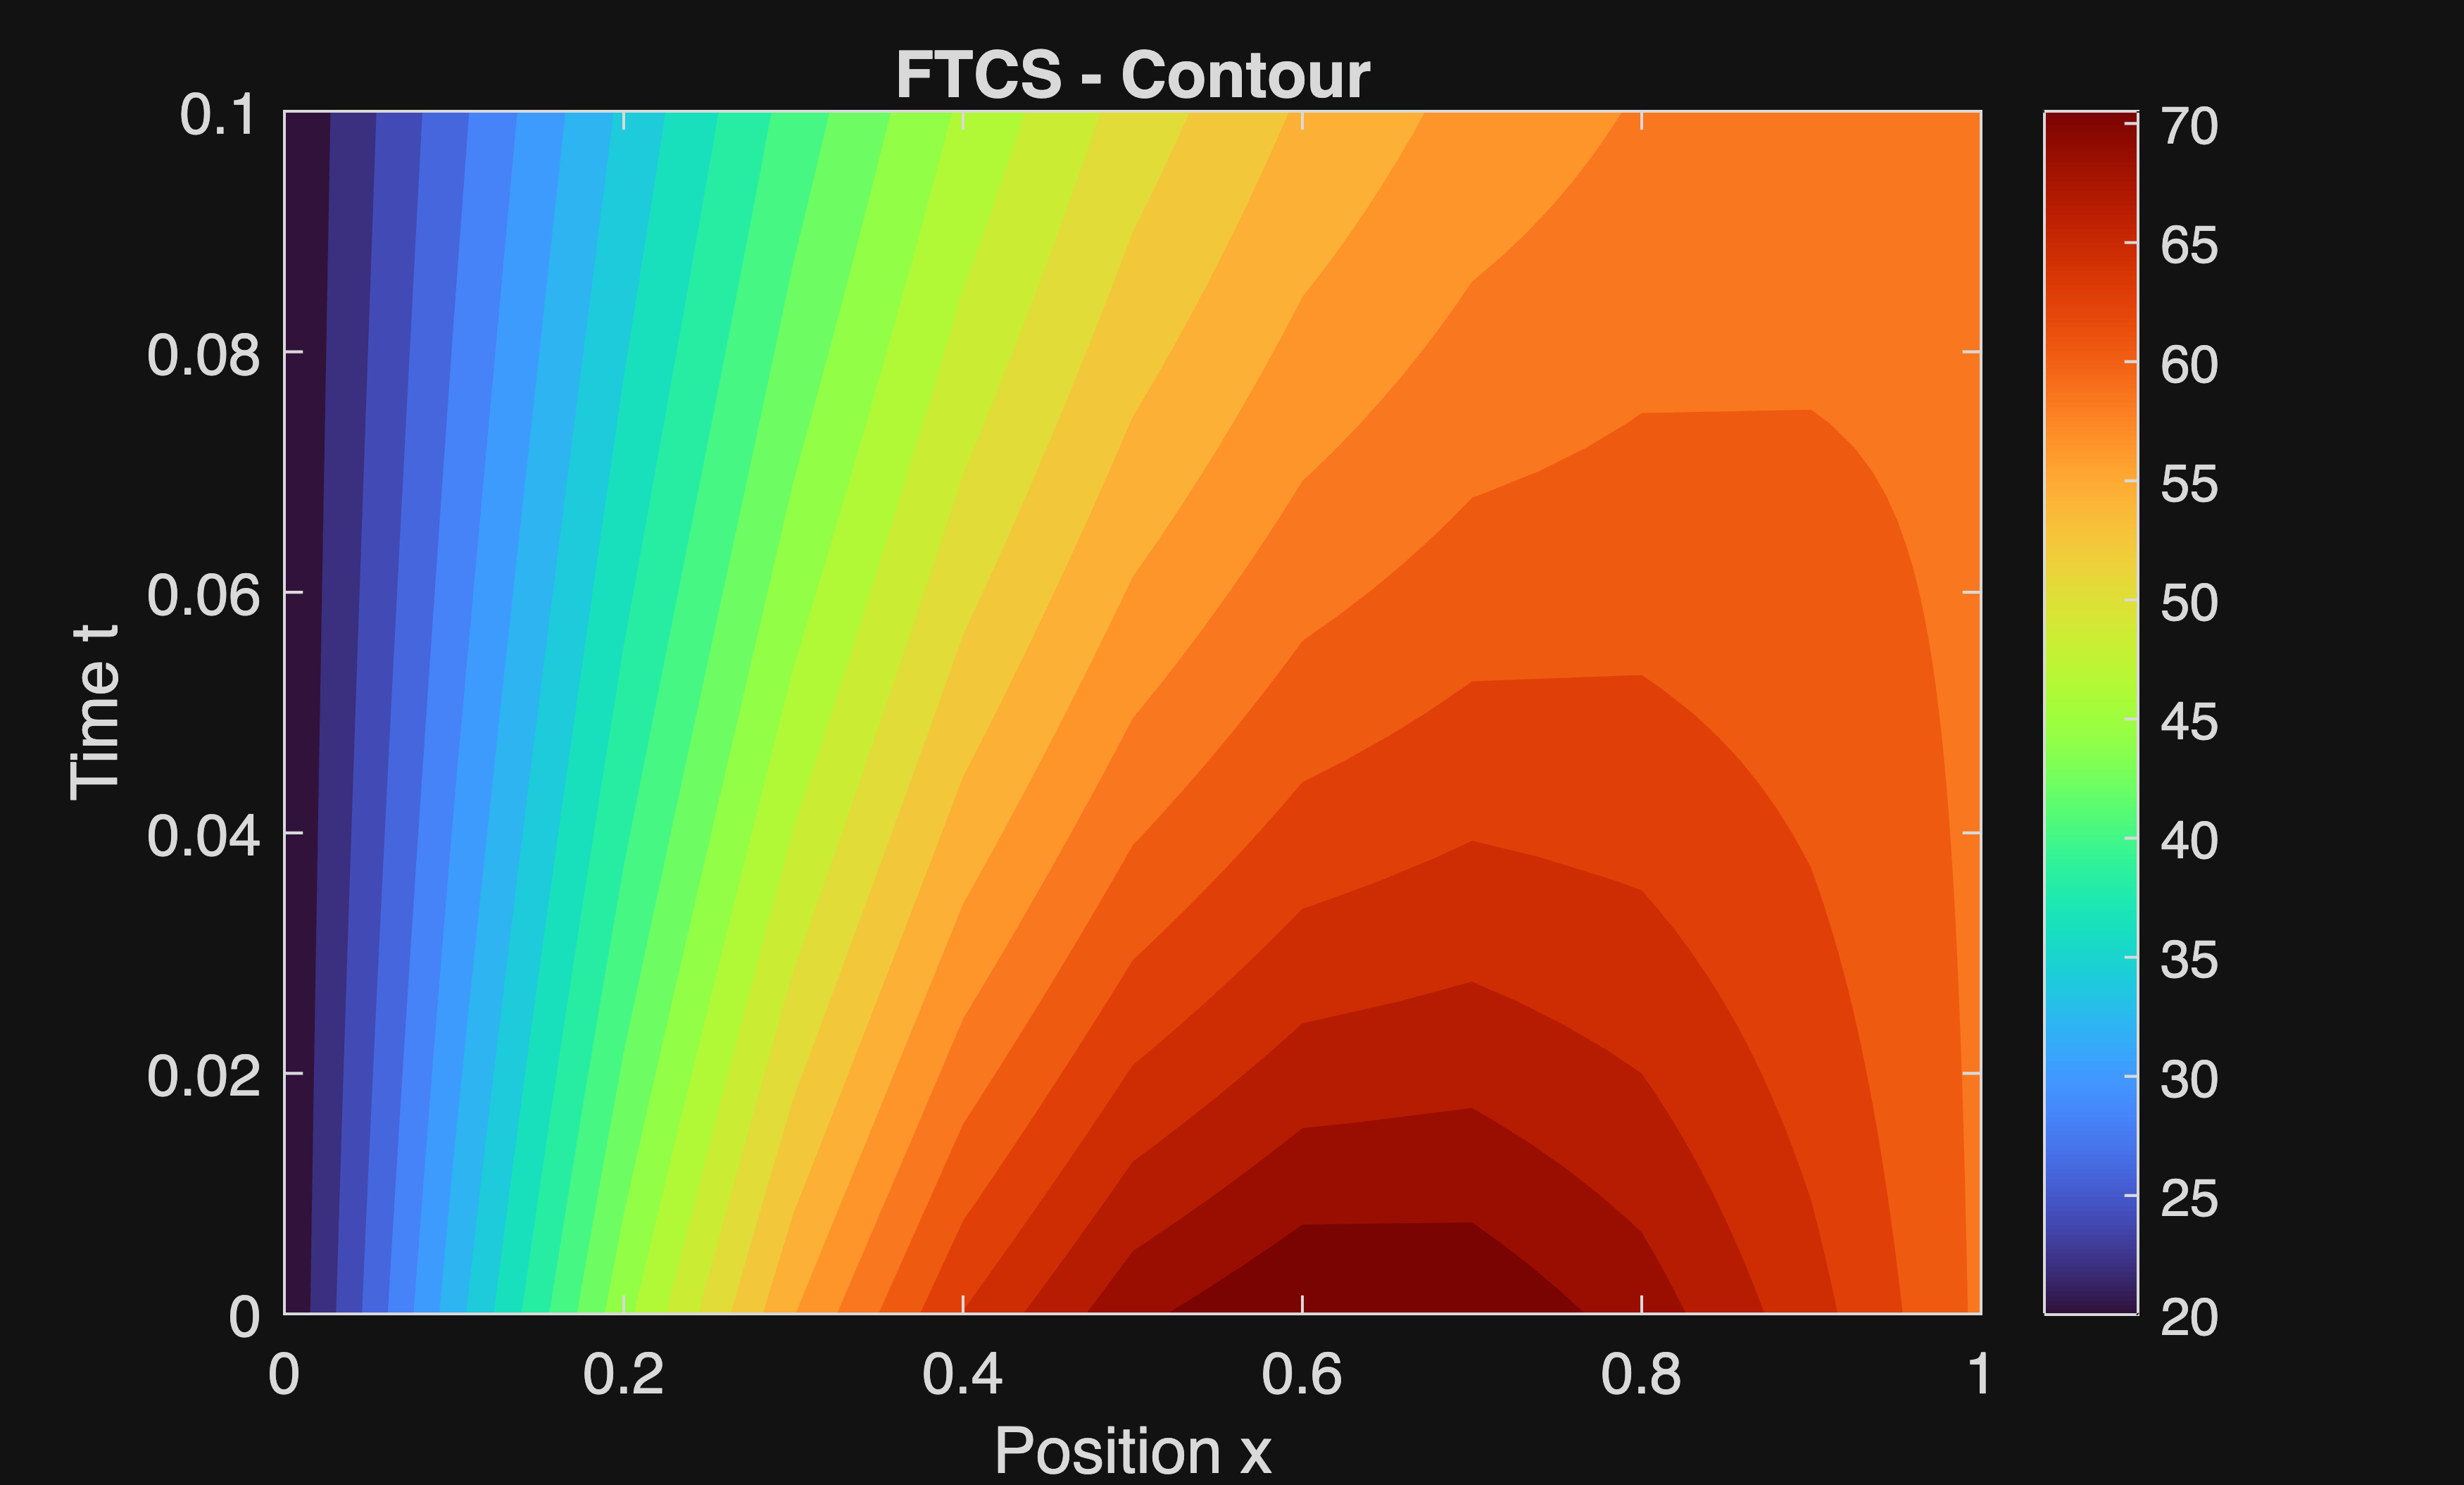

In [1]:
clc; clear; close all;

% Parameters
L = 1;
T = 0.1;
h = 0.1;
k = 0.002;

% Computational grid
x = 0:h:L;
t = 0:k:T;

Nx = numel(x);
Nt = numel(t);
r = k/h^2;

% Solution matrix (space x time)
u = zeros(Nx, Nt);

% Initial condition
u(:,1) = (20 + 40*x + 30*sin(pi*x))';

% Dirichlet boundary conditions
u(1,:) = 20;
u(end,:) = 60;

% FTCS method
i = 2:Nx-1;

for j = 1:Nt-1
    u(i,j+1) = u(i,j) + r*( ...
        u(i-1,j) - 2*u(i,j) + u(i+1,j));
end

% 2D Contour

figure;
contourf(x, t, u', 25, 'LineColor','none');

colormap(turbo);
colorbar;

xlabel('Position x');
ylabel('Time t');
title('FTCS - Contour');

axis tight;

In [2]:
drawnow;


## **Άσκηση 2.**

In [3]:
clc; clear;

% Parameters
L = 1;
T = 0.1;
h = 0.05;
k = 0.001;

% Computational grid
x = 0:h:L;
t = 0:k:T;

Nx = numel(x);
Nt = numel(t);
r = k/h^2;

% Stability condition
assert(r <= 0.5, 'FTCS is unstable');

% Solution matrix (space x time)
u = zeros(Nx,Nt);

% Initial condition
u(:,1) = (20 + 40*x + 30*sin(2*pi*x) ...
          + 20*x.*(1-x))';

% Dirichlet boundary conditions
u(1,:) = 20 + 10*sin(20*pi*t);
u(end,:) = 60 + 100*t;

% FTCS method
i = 2:Nx-1;

for j = 1:Nt-1
    u(i,j+1) = u(i,j) + r*( ...
        u(i-1,j) - 2*u(i,j) + u(i+1,j));
end

% Value at x = 0.35, t = 0.05
ix = round(0.35/h) + 1;
jt = round(0.05/k) + 1;

fprintf('u(0.35,0.05) = %.6f\n', u(ix,jt));

u(0.35,0.05) = 42.147594


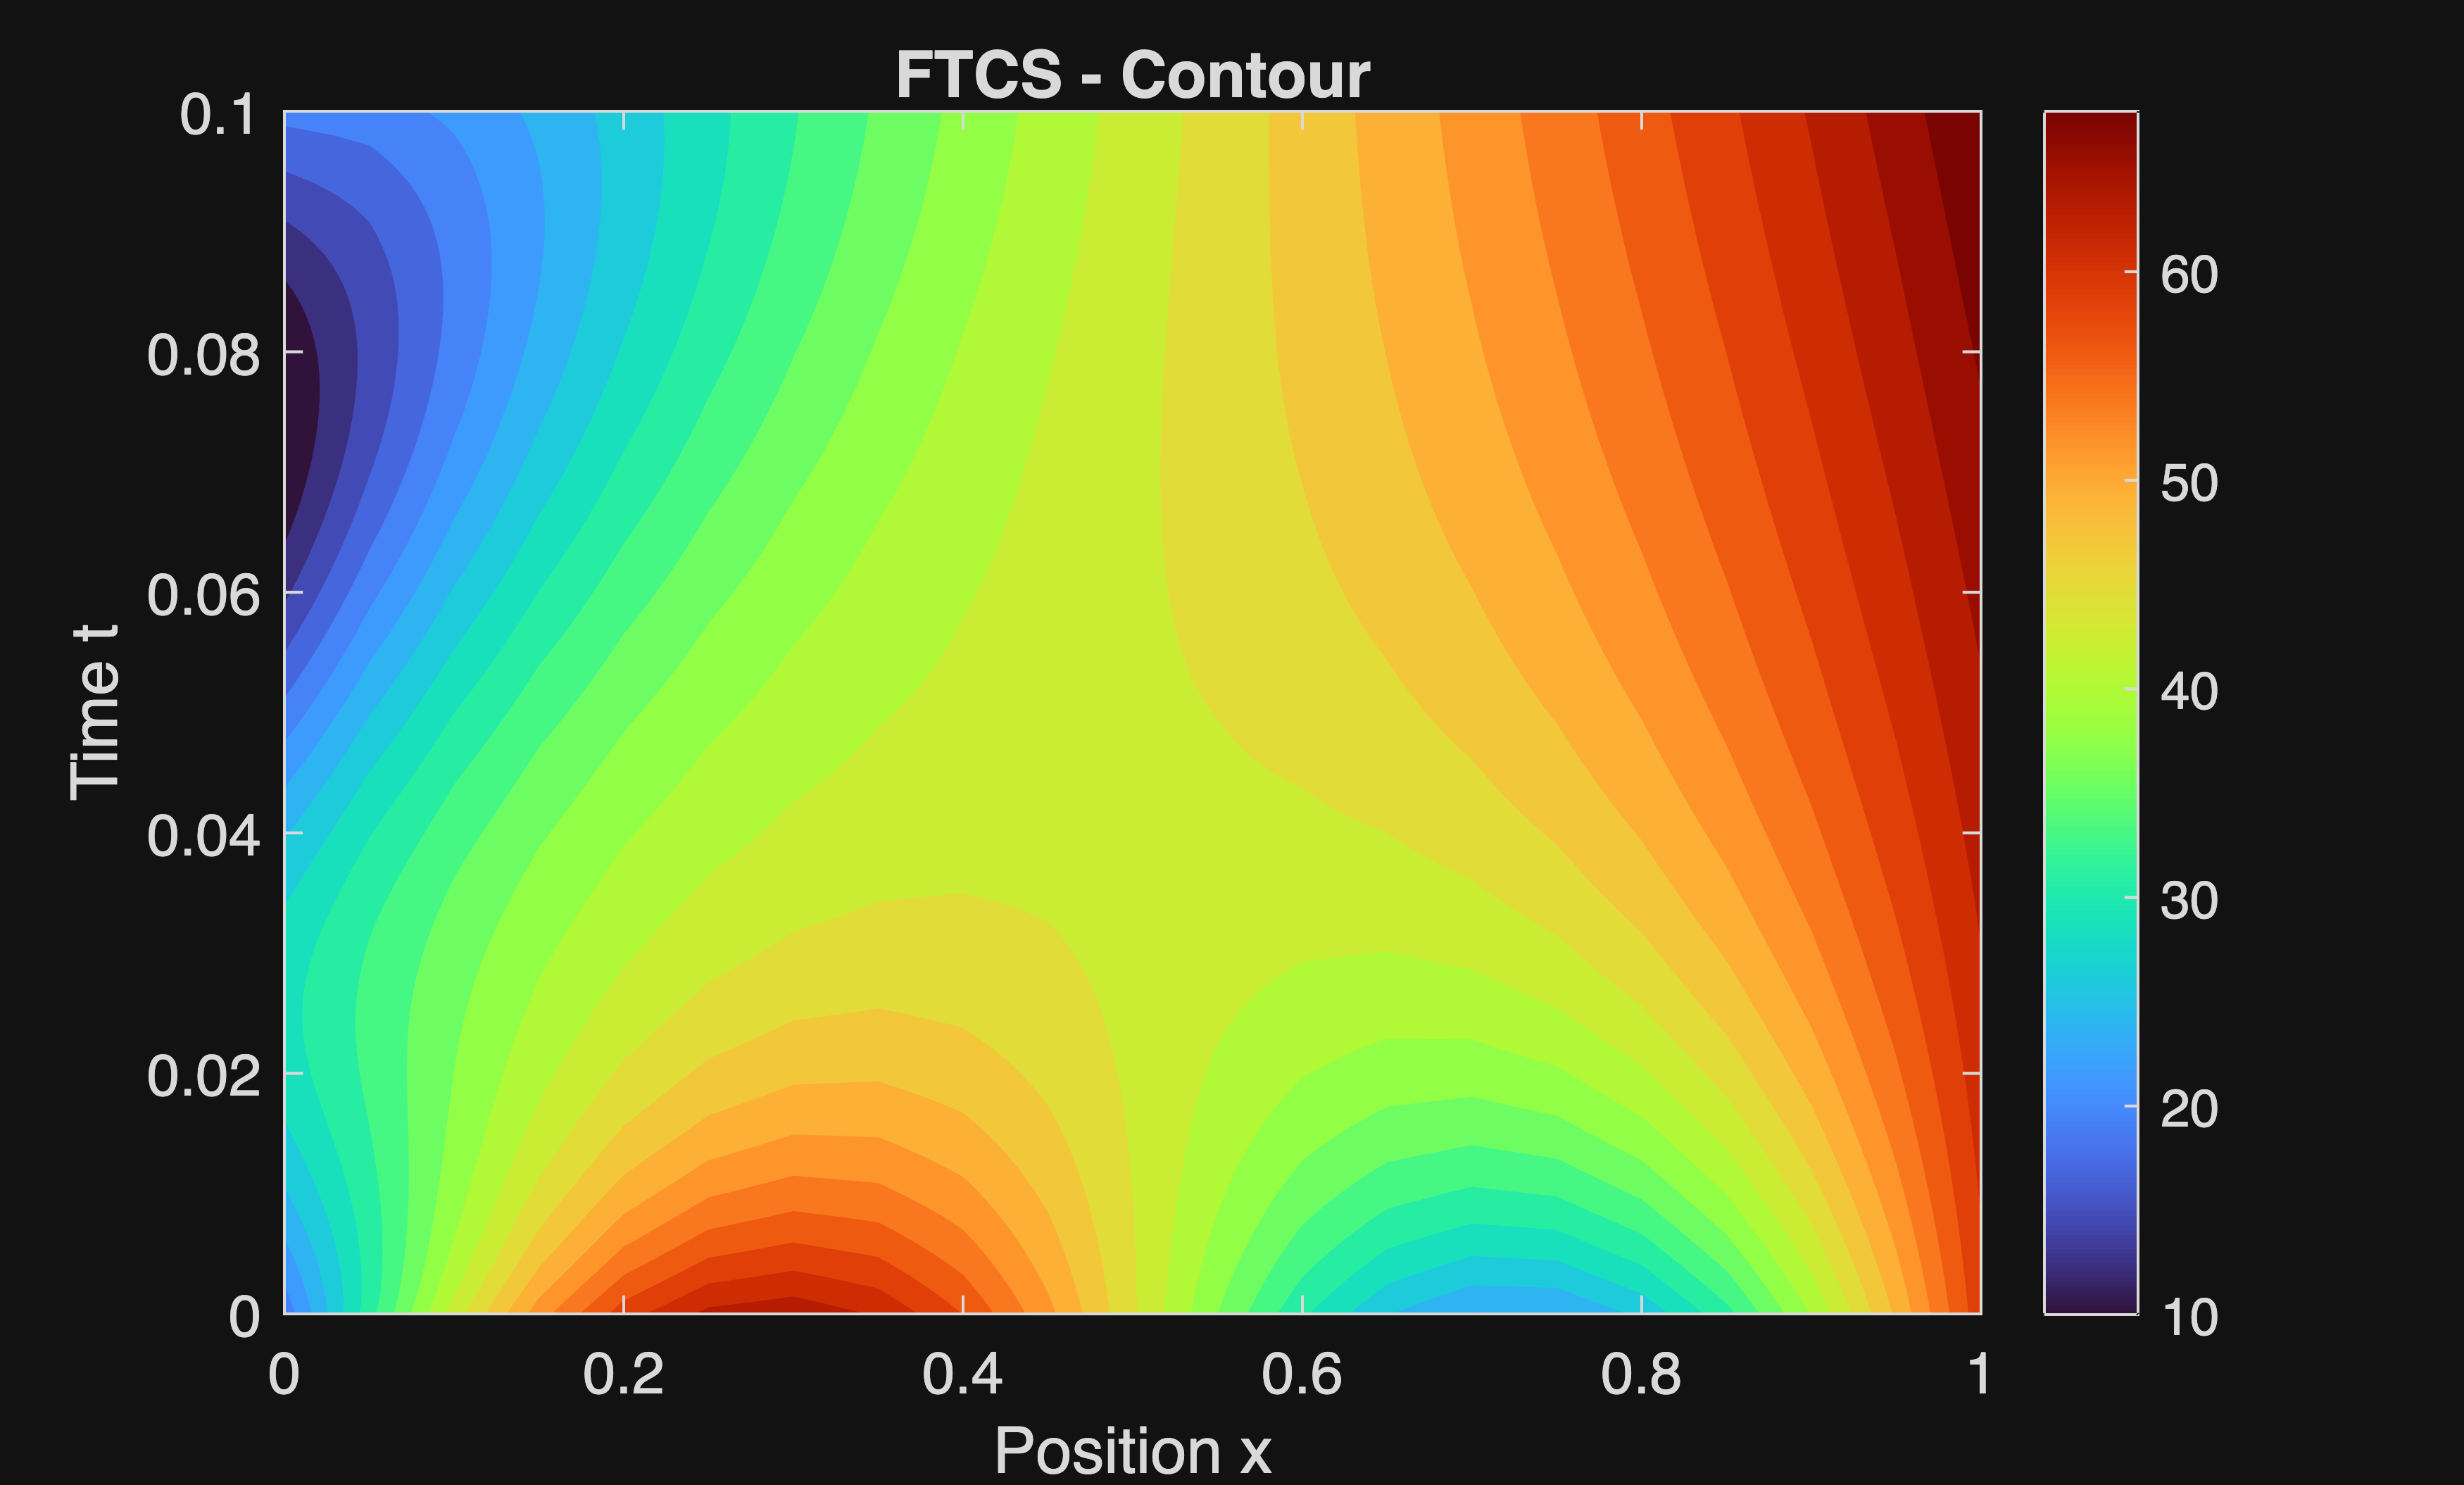

In [4]:

% 2D Contour
figure;
contourf(x, t, u', 25, 'LineColor','none');

colormap(turbo);
colorbar;

xlabel('Position x');
ylabel('Time t');
title('FTCS - Contour');

axis tight;

In [5]:
drawnow;

## **Άσκηση 3.**


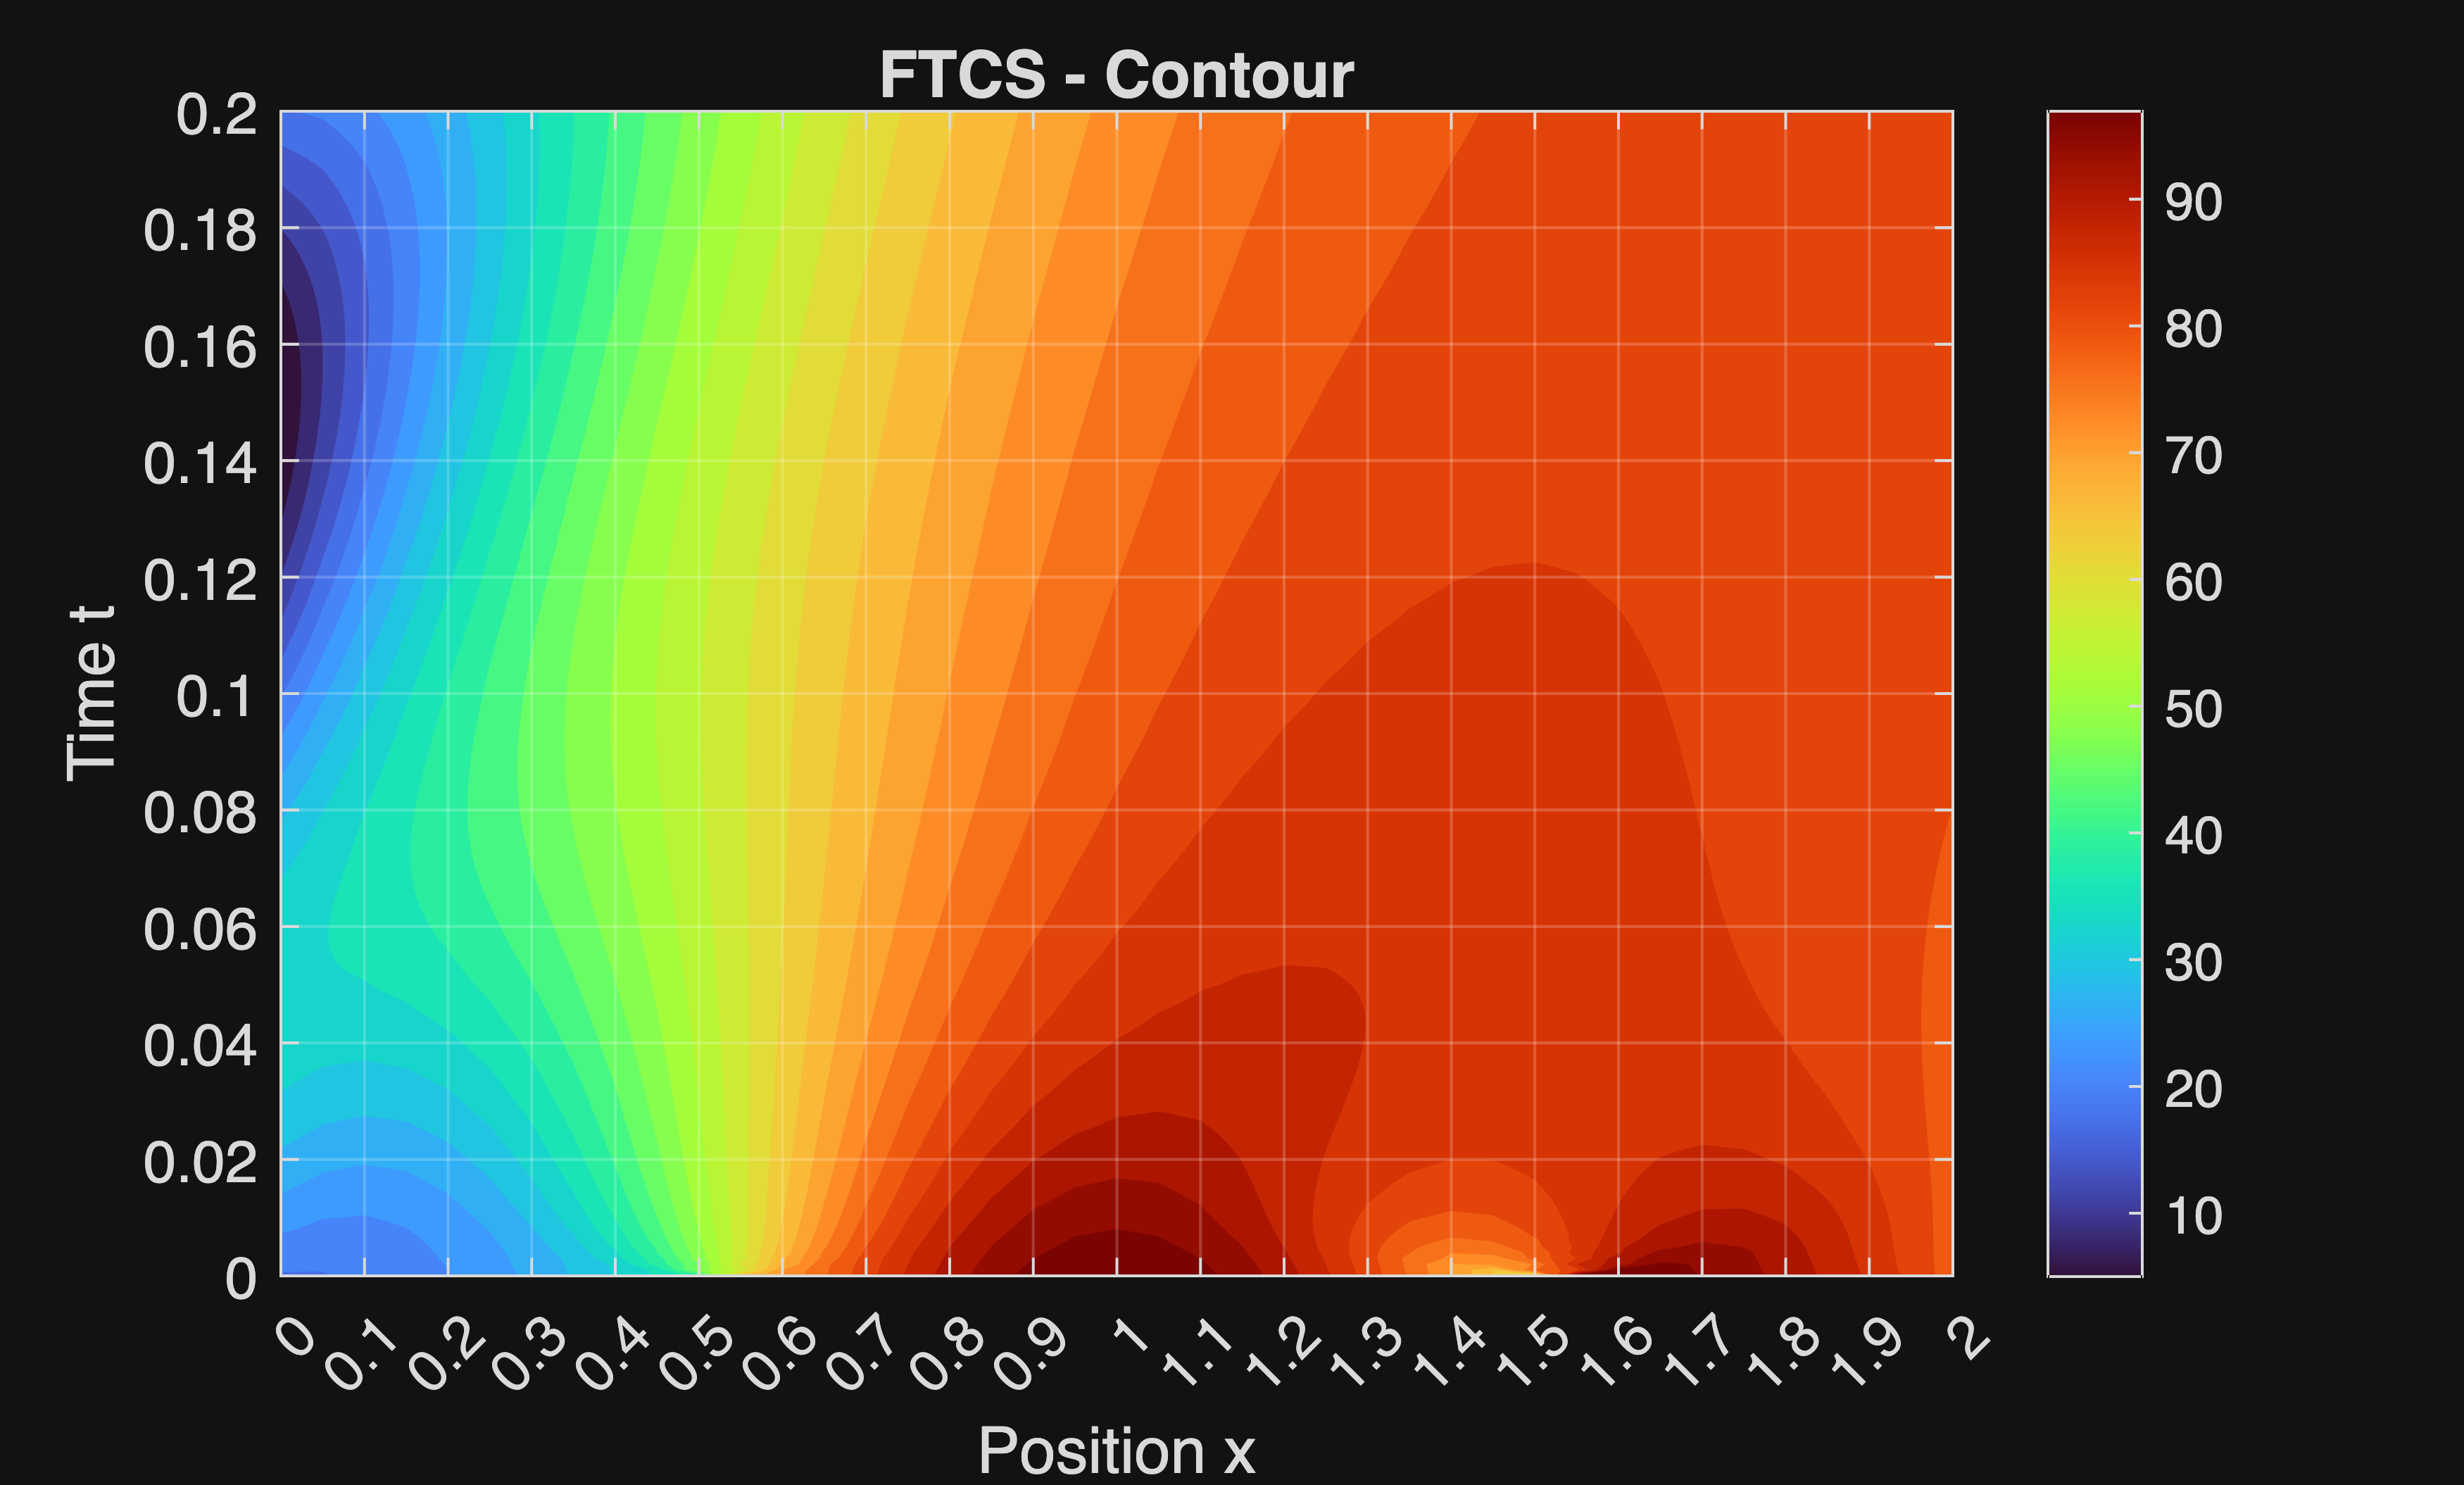

In [6]:

clc; clear;

% Parameters
L = 2;
T = 0.2;
h = 0.05;
k = 0.001;

% Computational grid
x = 0:h:L;
t = 0:k:T;

Nx = numel(x);
Nt = numel(t);
r = k/h^2;

% Stability condition
assert(r <= 0.5, 'FTCS is unstable');

% Solution matrix (space x time)
u = zeros(Nx,Nt);

% Initial condition
u(x <= 0.5,1) = 20 + 80*x(x <= 0.5).^2;

u(x > 0.5 & x <= 1.5,1) = ...
    60 + 40*sin(pi*(x(x > 0.5 & x <= 1.5)-0.5));

u(x > 1.5,1) = ...
    100 - 80*(x(x > 1.5)-1.5).^2;

% Dirichlet boundary conditions
u(1,:) = 20 + 15*sin(10*pi*t);
u(end,:) = 80 + 20*t;

% FTCS method
i = 2:Nx-1;

for j = 1:Nt-1
    u(i,j+1) = u(i,j) + r*( ...
        u(i-1,j) - 2*u(i,j) + u(i+1,j));
end

% 2D Contour
figure;
contourf(x,t,u',30,'LineColor','none');

colormap(turbo);
colorbar;

xlabel('Position x');
ylabel('Time t');
title('FTCS - Contour');

xticks(0:2*h:L);
yticks(0:20*k:T);

grid on;
set(gca,'Layer','top','GridAlpha',0.2);
axis tight;

In [7]:

drawnow;

% Maximum temperature
umax = max(u(:));
[ix, jt] = find(u == umax, 1);

fprintf('Max = %.2f at x = %.2f, t = %.3f\n', ...
    umax, x(ix), t(jt));

Max = 100.00 at x = 1.00, t = 0.000



## Άσκηση 4.

In [8]:

clc; clear;

% Parameters
L = 2;
T = 0.3;
h = 0.05;
k = 0.001;

% Computational grid
x = 0:h:L;
t = 0:k:T;

Nx = numel(x);
Nt = numel(t);
r = k/h^2;

% Stability condition
assert(r <= 0.5, 'FTCS is unstable');

% Solution matrix (space x time)
u = zeros(Nx,Nt);

% Initial condition
u(:,1) = 50;

% Left Dirichlet boundary
a = t <= 0.1;
b = t > 0.1;

u(1,a) = 50 + 20*sin(5*pi*t(a));
u(1,b) = 70 - 100*(t(b)-0.1);

% Right Dirichlet boundary
a = t <= 0.15;
b = t > 0.15;

u(end,a) = 50 + 100*t(a);
u(end,b) = 65 - 200*(t(b)-0.15).^2;

% FTCS method
i = 2:Nx-1;

for j = 1:Nt-1
    u(i,j+1) = u(i,j) + r*( ...
        u(i-1,j) - 2*u(i,j) + u(i+1,j));
end

% Maximum temperature
umax = max(u(:));
[ix,jt] = find(u == umax,1);

fprintf('Max = %.2f at x = %.2f, t = %.3f\n', ...
    umax, x(ix), t(jt));

Max = 70.00 at x = 0.00, t = 0.100


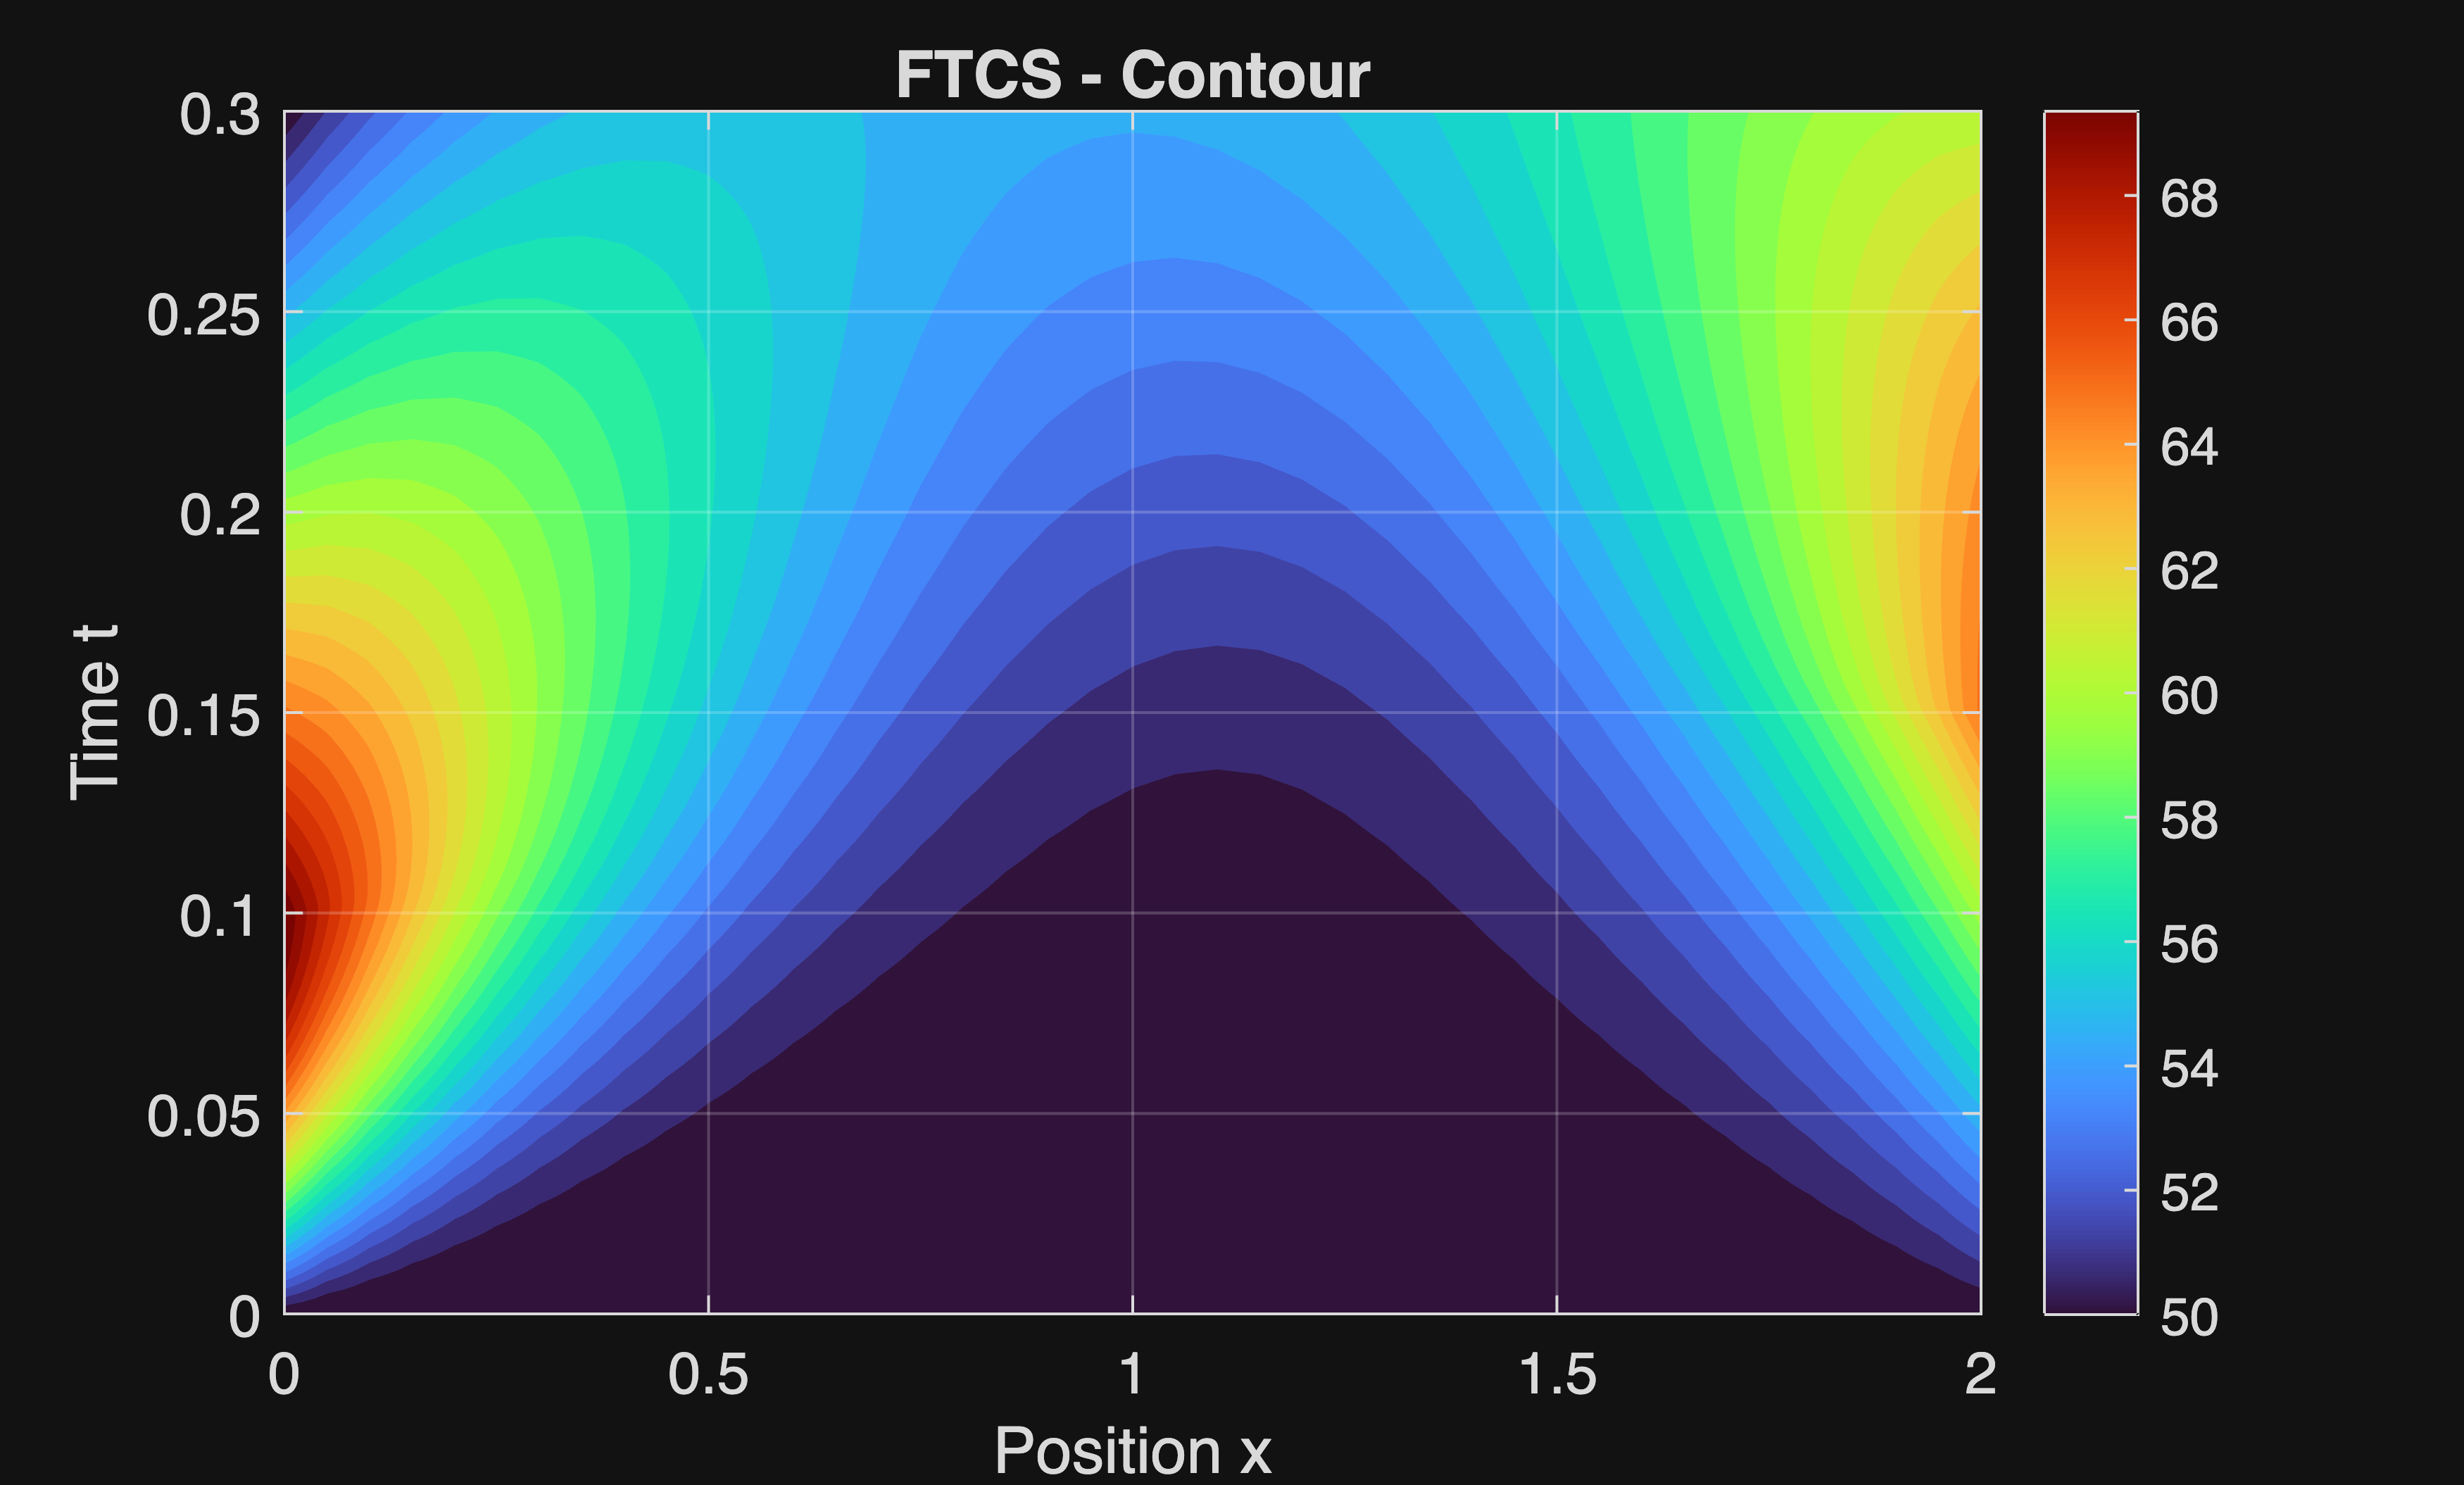

In [9]:

% 2D Contour
figure;
contourf(x,t,u',30,'LineColor','none');

colormap(turbo);
colorbar;

xlabel('Position x');
ylabel('Time t');
title('FTCS - Contour');

grid on;
set(gca,'Layer','top','GridAlpha',0.2);
axis tight;

In [10]:

drawnow;

## Άσκηση 5.


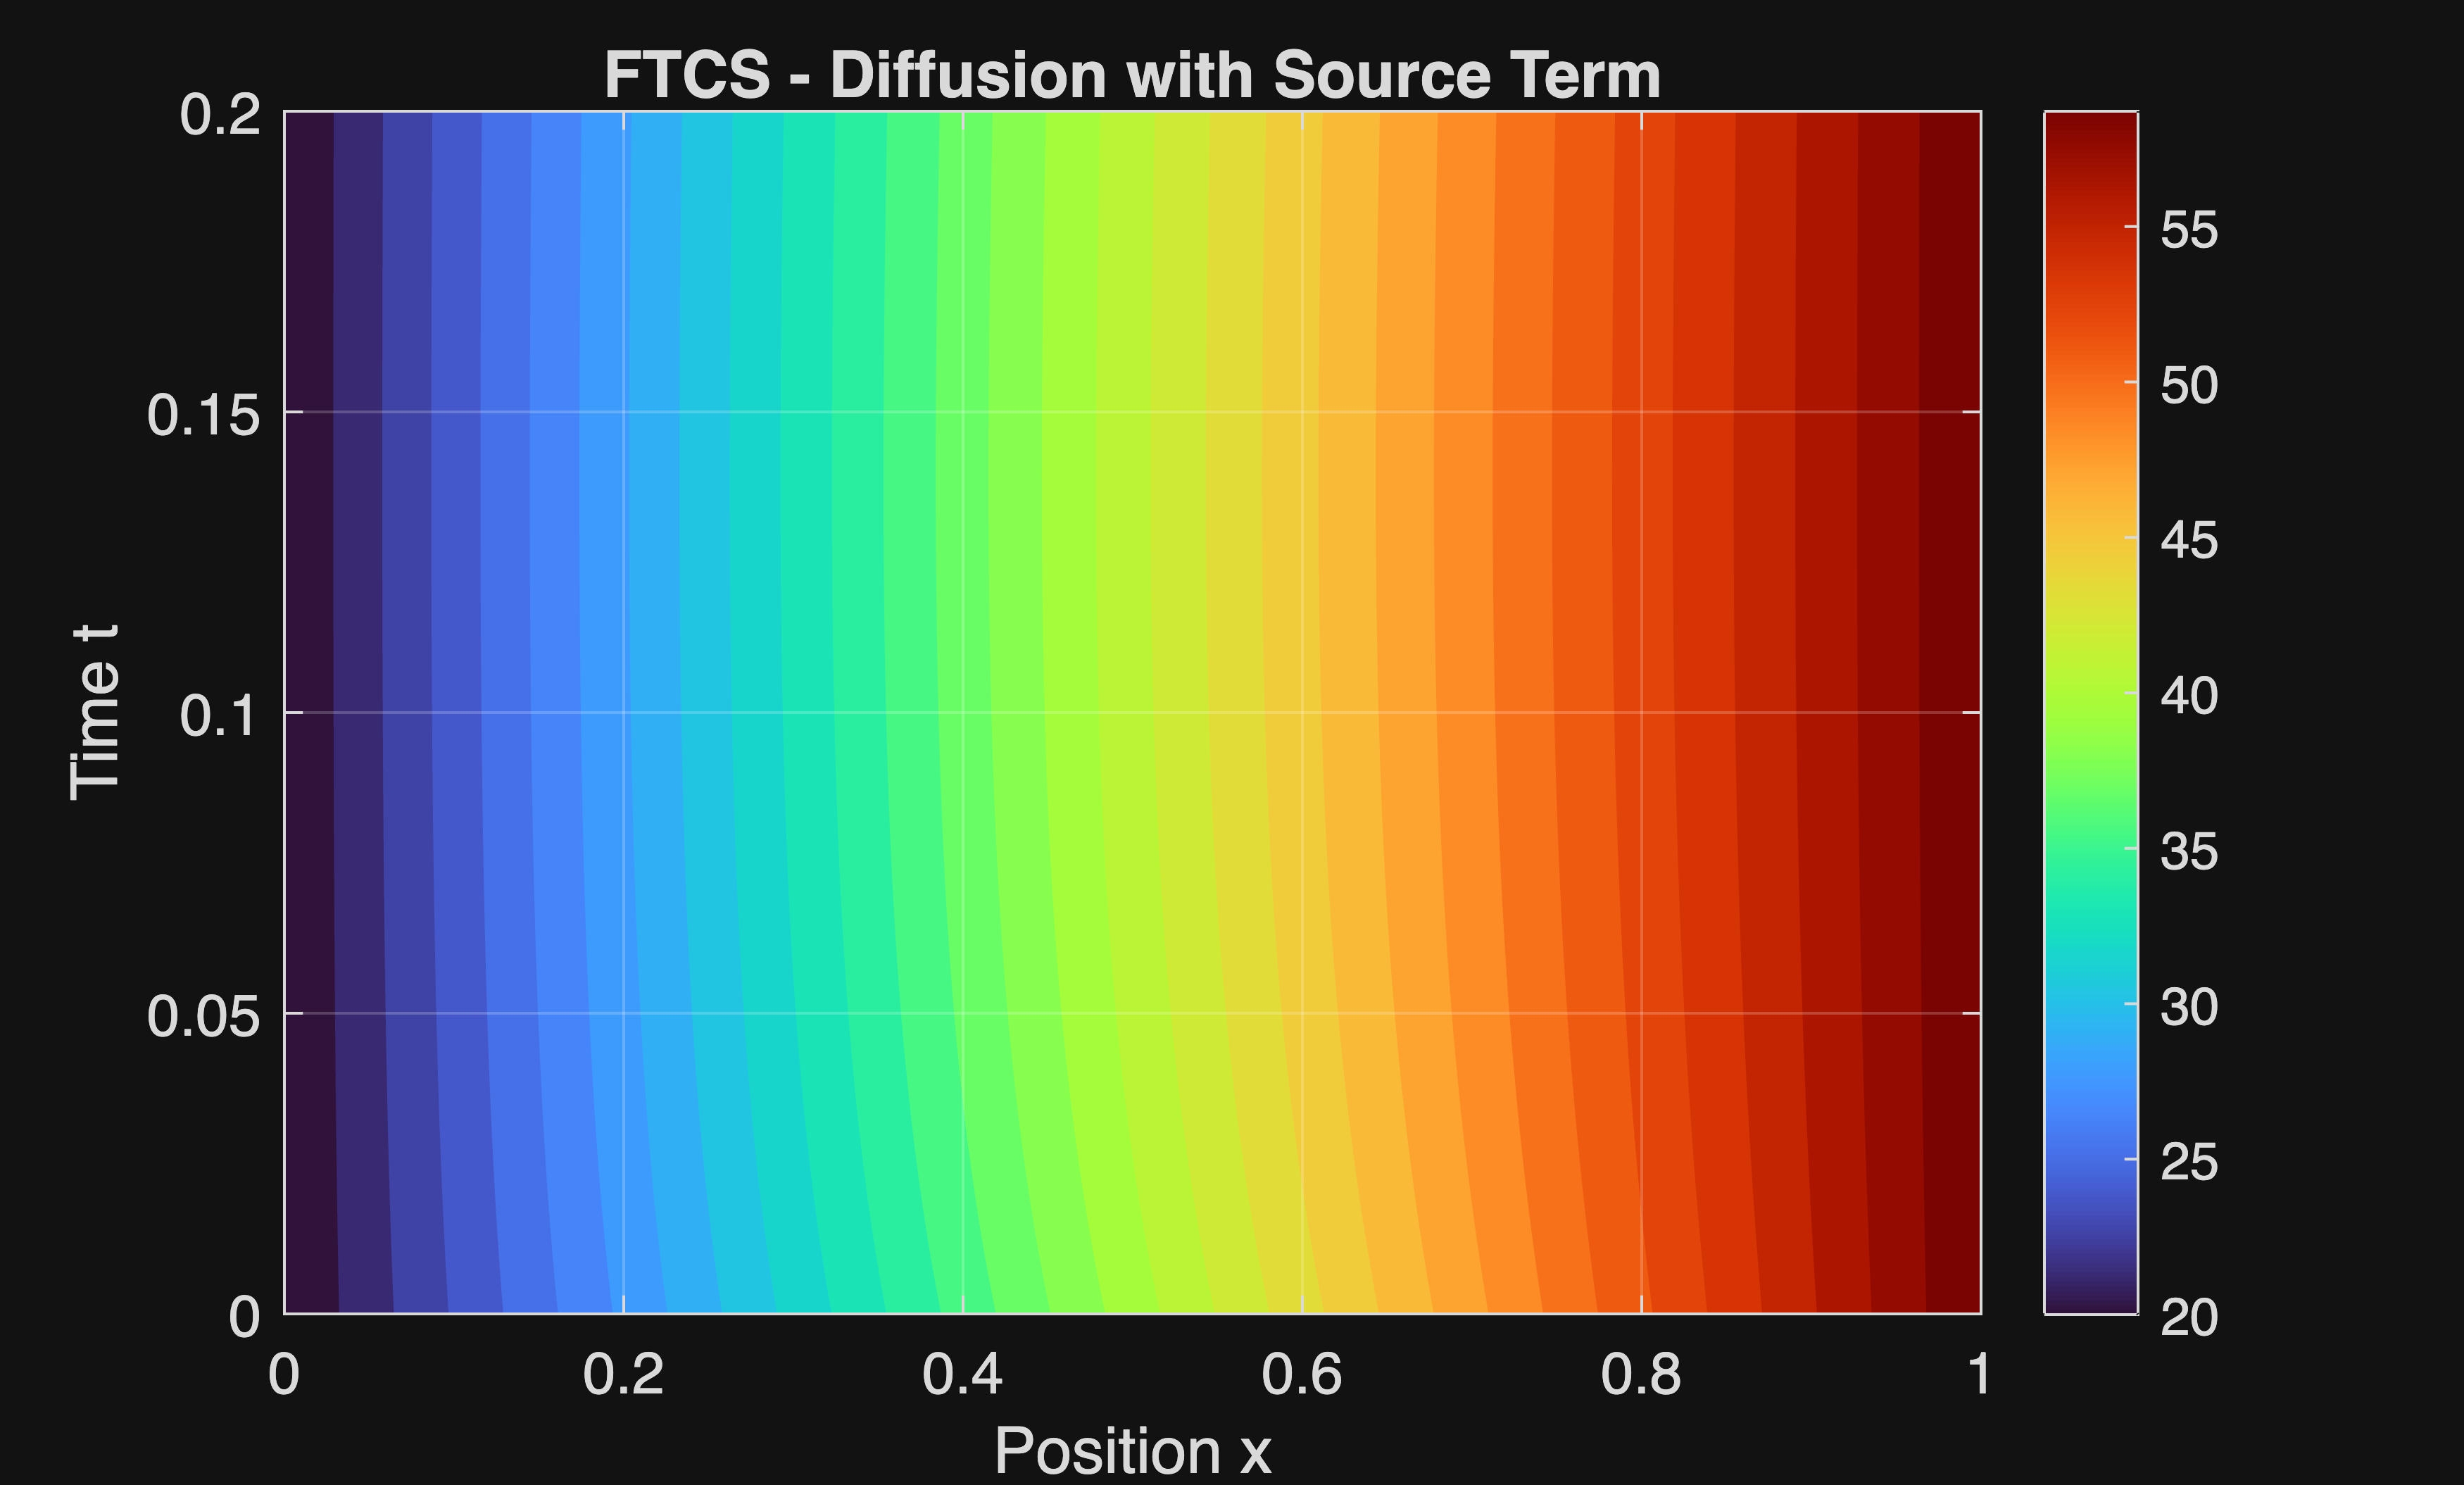

In [11]:

clc; clear;

% Parameters
L = 1;
T = 0.2;
h = 0.05;
k = 0.001;

% Computational grid
x = 0:h:L;
t = 0:k:T;

Nx = numel(x);
Nt = numel(t);
r = k/h^2;

% Stability condition
assert(r <= 0.5, 'FTCS is unstable');

% Solution matrix (space x time)
u = zeros(Nx,Nt);

% Initial condition
u(:,1) = (20 + 40*x)';

% Dirichlet boundary conditions
u(1,:) = 20;
u(end,:) = 60;

% FTCS method with source term
i = 2:Nx-1;

for j = 1:Nt-1
    S = 30*exp(-5*t(j))*sin(pi*x(i))';

    u(i,j+1) = u(i,j) + r*( ...
        u(i-1,j) - 2*u(i,j) + u(i+1,j)) ...
        + k*S;
end

% 2D Contour
figure;
contourf(x,t,u',30,'LineColor','none');

colormap(turbo);
colorbar;

xlabel('Position x');
ylabel('Time t');
title('FTCS - Diffusion with Source Term');

grid on;
set(gca,'Layer','top','GridAlpha',0.2);
axis tight;

In [12]:

drawnow;


## Άσκηση 6.

Ο όρος πηγής υπολογίζεται από τη γνωστή τιμή \$u_i^j\$


στο προηγούμενο χρονικό επίπεδο. Έτσι, η μέθοδος


παραμένει ρητή (Explicit FTCS).


$$u_i^{j+1} =u_i^j +r(u_{i-1}^j -2u_i^j +u_{i+1}^j )+3ku_i^j$$



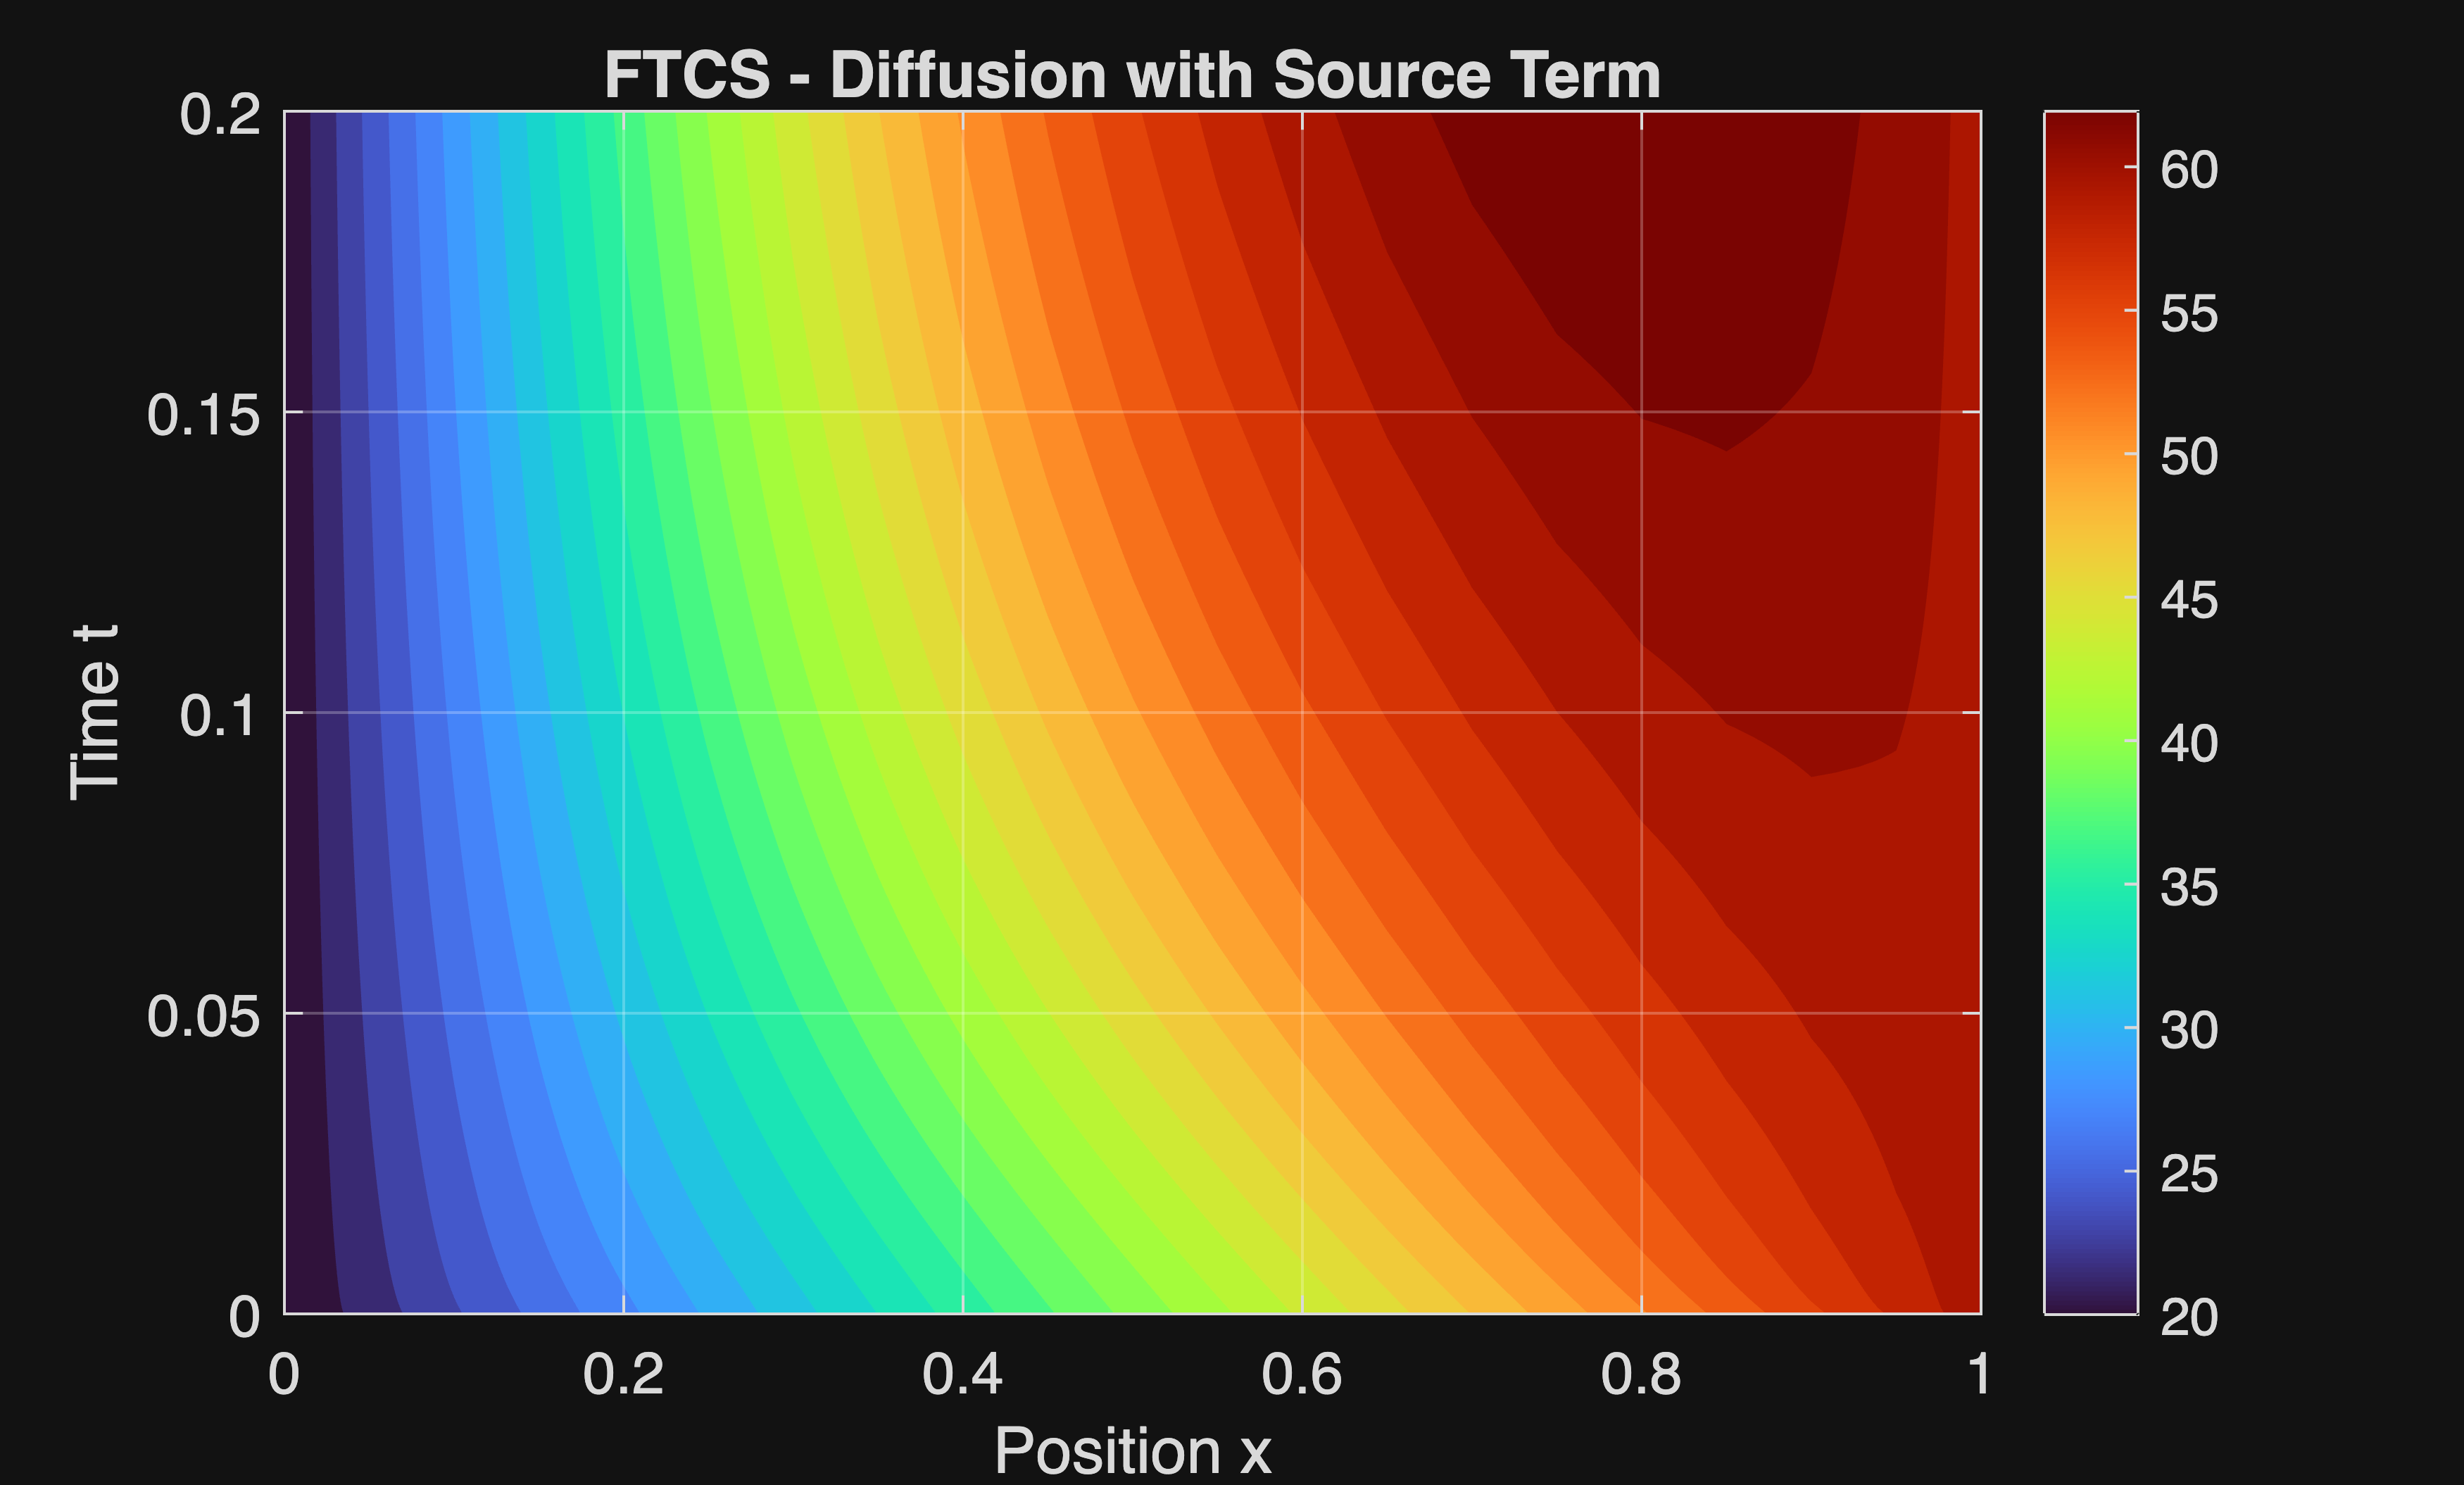

In [13]:

clc; clear;

% Parameters
L = 1;
T = 0.2;
h = 0.05;
k = 0.001;

% Computational grid
x = 0:h:L;
t = 0:k:T;

Nx = numel(x);
Nt = numel(t);
r = k/h^2;

% Stability condition
assert(r <= 0.5, 'FTCS is unstable');

% Solution matrix (space x time)
u = zeros(Nx,Nt);

% Initial condition
u(:,1) = (20 + 40*x)';

% Dirichlet boundary conditions
u(1,:) = 20;
u(end,:) = 60;

i = 2:Nx-1;

for j = 1:Nt-1
    u(i,j+1) = u(i,j) + r*( ...
        u(i-1,j) - 2*u(i,j) + u(i+1,j)) ...
        + 3*k*u(i,j);
end

% 2D Contour
figure;
contourf(x,t,u',30,'LineColor','none');

colormap(turbo);
colorbar;

xlabel('Position x');
ylabel('Time t');
title('FTCS - Diffusion with Source Term');

axis tight;
grid on;

In [14]:
drawnow;

## Άσκηση 7.

1. Εσωτερικά σημεία


Εφαρμόζουμε τη μέθοδο FTCS:


 $u_i^{j+1} =u_i^j +r(u_{i-1}^j -2u_i^j +u_{i+1}^j )$      όπου $r=\frac{k}{h^2 }$.


2. Αριστερό άκρο (i = 1)


$$u_1^{j+1} =u_1^j +r(u_0^j -2u_1^j +u_2^j )$$

Δεν γνωρίζουμε το \$u_{o}\$ επομένως πρέπει να το υπολογίσουμε μέσο των συνοριακών!


Εφαρμόζουμε Centered Difference στην οριακή συνθήκη:


$$\frac{u_2^j -u_0^j }{2h}=u_1^j$$


Λύνουμε ως προς το εικονικό σημείο:


$$u_0^j =u_2^j -2hu_1^j$$


Αντικαθιστούμε στον τύπο FTCS:


$$u_1^{j+1} =u_1^j +r(u_2^j -2hu_1^j -2u_1^j +u_2^j )$$


Ομαδοποιώντας τους όρους, προκύπτει:


$$u_1^{j+1} =u_1^j +2r[u_2^j -(1+h)u_1^j ]$$


3. Δεξί άκρο $(i=N_x )$


Εφαρμόζουμε Centered Difference στην οριακή συνθήκη:


$$\frac{u_{N_x +1}^j -u_{N_x -1}^j }{2h}=-u_{N_x }^j$$


Λύνουμε ως προς το εικονικό σημείο:


$$u_{N_x +1}^j =u_{N_x -1}^j -2hu_{N_x }^j$$


Αντικαθιστούμε στον τύπο FTCS:


$$u_{N_x }^{j+1} =u_{N_x }^j +r(u_{N_x -1}^j -2u_{N_x }^j +u_{N_x -1}^j -2hu_{N_x }^j )$$


Ομαδοποιώντας τους όρους, προκύπτει:


$$u_{N_x }^{j+1} =u_{N_x }^j +2r[u_{N_x -1}^j -(1+h)u_{N_x }^j ]$$



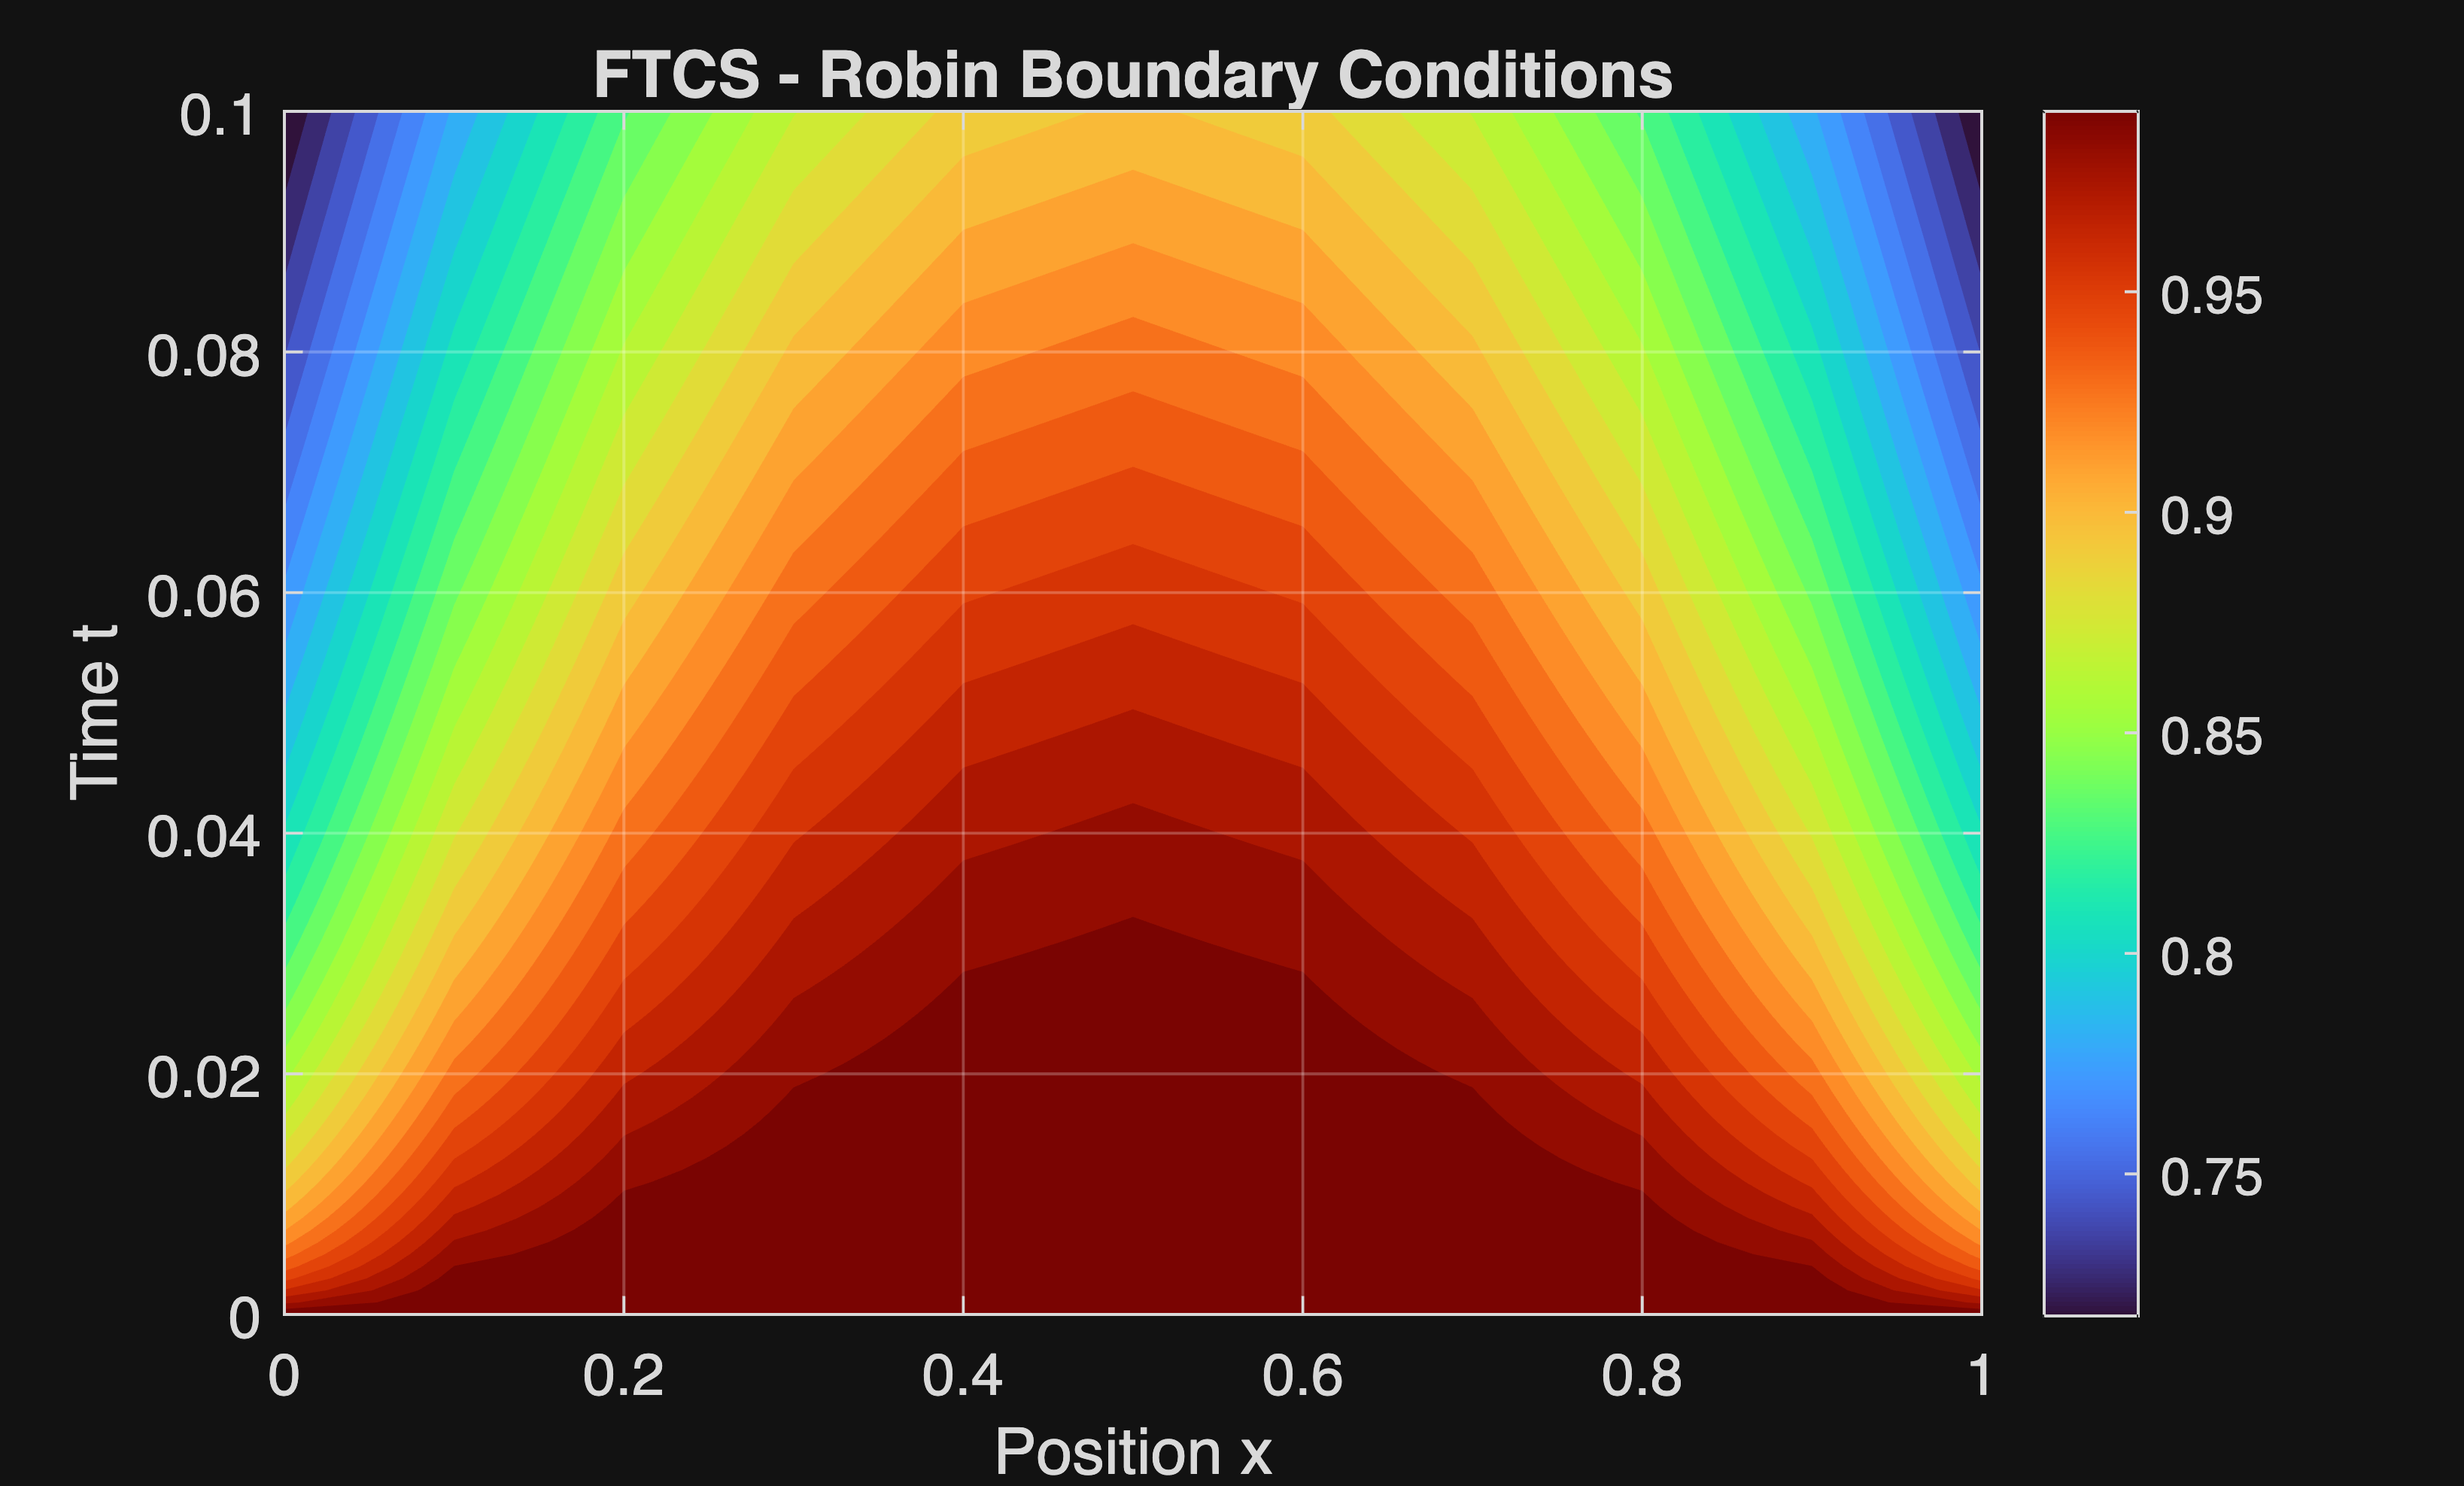

In [15]:

clc; clear;

% Parameters
L = 1;
T = 0.1;
h = 0.1;
k = 0.001;

% Computational grid
x = 0:h:L;
t = 0:k:T;

Nx = numel(x);
Nt = numel(t);
r = k/h^2;

% Solution matrix (space x time)
u = zeros(Nx,Nt);

% Initial condition
u(:,1) = 1;

% FTCS method
i = 2:Nx-1;

for j = 1:Nt-1

    % Interior points
    u(i,j+1) = u(i,j) + r*( ...
        u(i-1,j) - 2*u(i,j) + u(i+1,j));

    % Left Robin boundary
    u(1,j+1) = u(1,j) + 2*r*( ...
        u(2,j) - (1+h)*u(1,j));

    % Right Robin boundary
    u(end,j+1) = u(end,j) + 2*r*( ...
        u(end-1,j) - (1+h)*u(end,j));

end

% 2D Contour
figure;
contourf(x,t,u',30,'LineColor','none');

colormap(turbo);
colorbar;

xlabel('Position x');
ylabel('Time t');
title('FTCS - Robin Boundary Conditions');

axis tight;
grid on;

In [16]:
drawnow;
